# LEGACY: SemEval-2016 climate TF-IDF + Logistic Regression baseline

> **English auxiliary data (SemEval-2016 climate). Pipeline check only, not TerraLens results.**

**Legacy code.** Classical models are not part of the TerraLens Milestone 2 results; this notebook is kept only as
a record of the early pipeline check. It was split out of `notebooks/01_eda_semeval.ipynb` and uses
`legacy/baselines.py` and `legacy/configs/baseline.yaml`.

Figures are saved to `legacy/reports/figures/` and a summary to `legacy/reports/semeval_tfidf_baseline.md`.

## 0. Setup and data

In [1]:
import random
import re
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.pipeline import Pipeline

from terralens import LABELS
from terralens.data import PROJECT_ROOT, load_external
from terralens.evaluate import against_f1, confusion_df, macro_f1
from terralens.preprocess import clean_text

sys.path.insert(0, str(PROJECT_ROOT))  # so the repo-root `legacy` package is importable
from legacy.baselines import build_features, load_config  # noqa: E402

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DISCLAIMER = "English auxiliary data (SemEval-2016 climate). Pipeline check only, not TerraLens results."
FIG_DIR = PROJECT_ROOT / "legacy" / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
PALETTE = {"Favour": "#2a9d8f", "Against": "#e76f51", "None": "#8d99ae"}
SEMST_RE = re.compile(r"#semst\b", re.IGNORECASE)

sns.set_theme(style="whitegrid")


def save_fig(fig, name):
    """Stamp the disclaimer on a figure and save it to legacy/reports/figures/."""
    fig.text(0.5, 0.005, DISCLAIMER, ha="center", va="bottom", fontsize=8, color="#b00020", style="italic")
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    path = FIG_DIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"saved {path.relative_to(PROJECT_ROOT)}")
    return path


df = load_external("semeval_climate")
assert df["label"].notna().all() and set(df["label"]) <= set(LABELS)
print(f"{len(df)} tweets")

564 tweets


## 1. Baseline: TF-IDF (word 1-2 + char 2-5) + Logistic Regression

> **English auxiliary data (SemEval-2016 climate). Pipeline check only, not TerraLens results.**

* Train on **train + validation** (395 tweets), evaluate once on **test** (169 tweets). No tuning on test.
* Text goes through the project's `clean_text` (URLs, mentions removed, emoji → text, lower-cased), plus removal of
  `#SemST`, which carries no label information.
* Features: `FeatureUnion` of word 1-2-gram and char_wb 2-5-gram TF-IDF, using the vectoriser settings from
  `legacy/configs/baseline.yaml` (`min_df=2`, `sublinear_tf=True`).
* Classifier: `LogisticRegression(class_weight="balanced", max_iter=1000)`.

In [2]:
def prep(text):
    return clean_text(SEMST_RE.sub(" ", text), lowercase=True)


df["clean_text"] = df["text"].map(prep)
train = df[df.split.isin(["train", "validation"])]
test = df[df.split == "test"]
X_train, y_train = train["clean_text"].to_numpy(), train["label"].to_numpy()
X_test, y_test = test["clean_text"].to_numpy(), test["label"].to_numpy()
print(f"train+validation: {len(train)}  {train.label.value_counts().reindex(LABELS).to_dict()}")
print(f"test:             {len(test)}  {test.label.value_counts().reindex(LABELS).to_dict()}")

config = load_config(PROJECT_ROOT / "legacy" / "configs" / "baseline.yaml")
lr_model = Pipeline([
    ("tfidf", build_features(config["features"])),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)),
])
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)
print("feature dims:", {name: len(v.vocabulary_) for name, v in lr_model.named_steps["tfidf"].transformer_list})

train+validation: 395  {'Favour': 212, 'Against': 15, 'None': 168}
test:             169  {'Favour': 123, 'Against': 11, 'None': 35}


feature dims: {'word': 1020, 'char': 9555}


## 2. Majority-class baseline

In [3]:
majority = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
maj_pred = majority.predict(X_test)
print("majority class:", majority.classes_[np.argmax(majority.class_prior_)])

majority class: Favour


## 3. Results on test

> **English auxiliary data (SemEval-2016 climate). Pipeline check only, not TerraLens results.**

In [4]:
results = {}
for name, pred in [("Majority class", maj_pred), ("TF-IDF + LR", lr_pred)]:
    results[name] = {
        "accuracy": accuracy_score(y_test, pred),
        "macro_f1": macro_f1(y_test, pred),
        "against_f1": against_f1(y_test, pred),
    }
    print(f"===== {name} =====  ({DISCLAIMER})")
    print(classification_report(y_test, pred, labels=LABELS, digits=3, zero_division=0))
    print(f"Against-class F1: {results[name]['against_f1']:.3f}\n")

results_df = pd.DataFrame(results).T.round(3)
results_df

===== Majority class =====  (English auxiliary data (SemEval-2016 climate). Pipeline check only, not TerraLens results.)
              precision    recall  f1-score   support

      Favour      0.728     1.000     0.842       123
     Against      0.000     0.000     0.000        11
        None      0.000     0.000     0.000        35

    accuracy                          0.728       169
   macro avg      0.243     0.333     0.281       169
weighted avg      0.530     0.728     0.613       169

Against-class F1: 0.000

===== TF-IDF + LR =====  (English auxiliary data (SemEval-2016 climate). Pipeline check only, not TerraLens results.)
              precision    recall  f1-score   support

      Favour      0.795     0.821     0.808       123
     Against      0.000     0.000     0.000        11
        None      0.415     0.486     0.447        35

    accuracy                          0.698       169
   macro avg      0.403     0.436     0.418       169
weighted avg      0.665     0

,accuracy,macro_f1,against_f1
Majority class,0.728,0.281,0.0
TF-IDF + LR,0.698,0.418,0.0


saved legacy\reports\figures\semeval_confusion_matrix.png


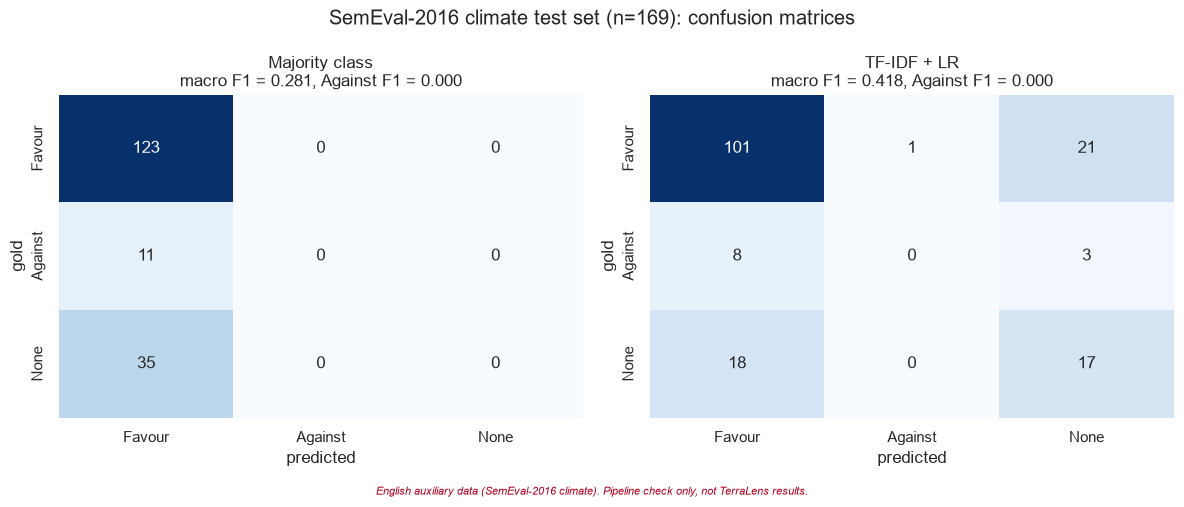

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, pred) in zip(axes, [("Majority class", maj_pred), ("TF-IDF + LR", lr_pred)]):
    cm = confusion_df(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 12})
    ax.set_xlabel("predicted")
    ax.set_ylabel("gold")
    ax.set_title(f"{name}\nmacro F1 = {results[name]['macro_f1']:.3f}, Against F1 = {results[name]['against_f1']:.3f}")
fig.suptitle("SemEval-2016 climate test set (n=169): confusion matrices")
save_fig(fig, "semeval_confusion_matrix.png")
plt.show()

## 4. Top 10 most informative features per class (LR)

Largest positive coefficients for each class in the multinomial LR. `w:` = word n-gram, `c:` = char n-gram
(spaces shown as `␣`).

saved legacy\reports\figures\semeval_lr_top_features.png


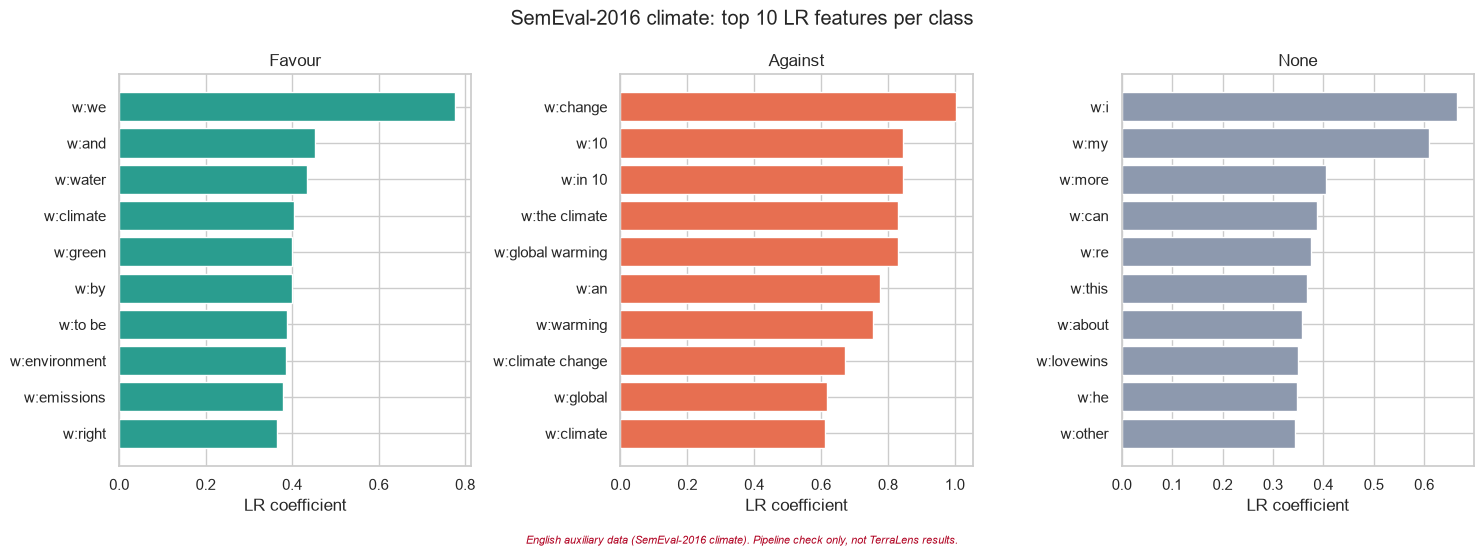

,Favour,Against,None
0,w:we (0.776),w:change (1.003),w:i (0.666)
1,w:and (0.452),w:10 (0.844),w:my (0.61)
2,w:water (0.434),w:in 10 (0.844),w:more (0.405)
3,w:climate (0.405),w:the climate (0.831),w:can (0.387)
4,w:green (0.401),w:global warming (0.829),w:re (0.376)
5,w:by (0.399),w:an (0.775),w:this (0.367)
6,w:to be (0.388),w:warming (0.755),w:about (0.358)
7,w:environment (0.386),w:climate change (0.673),w:lovewins (0.35)
8,w:emissions (0.378),w:global (0.618),w:he (0.348)
9,w:right (0.365),w:climate (0.612),w:other (0.344)


In [6]:
clf = lr_model.named_steps["clf"]
feat_names = np.concatenate([
    [f"{'w' if name == 'word' else 'c'}:{f}" for f in vec.get_feature_names_out()]
    for name, vec in lr_model.named_steps["tfidf"].transformer_list
])
feat_names = np.array([f.replace(" ", "␣") if f.startswith("c:") else f for f in feat_names])

top_feats = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
for ax, label in zip(axes, LABELS):
    k = list(clf.classes_).index(label)
    idx = np.argsort(clf.coef_[k])[::-1][:10]
    top_feats[label] = list(zip(feat_names[idx], clf.coef_[k][idx].round(3)))
    ax.barh(feat_names[idx][::-1], clf.coef_[k][idx][::-1], color=PALETTE[label])
    ax.set_title(label)
    ax.set_xlabel("LR coefficient")
fig.suptitle("SemEval-2016 climate: top 10 LR features per class")
save_fig(fig, "semeval_lr_top_features.png")
plt.show()

pd.DataFrame({label: [f"{f} ({c})" for f, c in top_feats[label]] for label in LABELS})

## 5. Write `legacy/reports/semeval_tfidf_baseline.md`

In [7]:
def md_table(frame):
    frame = frame.reset_index()
    head = "| " + " | ".join(map(str, frame.columns)) + " |"
    sep = "|" + "---|" * len(frame.columns)
    rows = ["| " + " | ".join(map(str, r)) + " |" for r in frame.itertuples(index=False)]
    return "\n".join([head, sep, *rows])


lr_rep = classification_report(y_test, lr_pred, labels=LABELS, output_dict=True, zero_division=0)
per_class = pd.DataFrame({l: lr_rep[l] for l in LABELS}).T[["precision", "recall", "f1-score", "support"]]
per_class["support"] = per_class["support"].astype(int)
per_class = per_class.round(3)
per_class.index.name = "class"

lr_cm = confusion_df(y_test, lr_pred)
lr_cm.columns = [f"pred {c}" for c in lr_cm.columns]
r_lr, r_maj = results["TF-IDF + LR"], results["Majority class"]
res_tbl = results_df.copy()
res_tbl.index.name = "model"

report = f"""# LEGACY: SemEval-2016 climate TF-IDF + LR baseline

> **{DISCLAIMER}**
> Legacy record of the early pipeline check. Classical models are not part of the TerraLens Milestone 2 results.
> Generated by `legacy/notebooks/semeval_tfidf_baseline.ipynb`. EDA of this data: `reports/eda_semeval.md`.

## Baseline (train+validation → test)

TF-IDF word 1-2-grams + char_wb 2-5-grams (`FeatureUnion`, `min_df=2`, sublinear TF) + `LogisticRegression(class_weight="balanced", max_iter=1000)`,
compared with a majority-class (`Favour`) baseline. Trained on {len(train)} tweets, evaluated once on {len(test)} test tweets.

{md_table(res_tbl)}

TF-IDF + LR per-class results on test:

{md_table(per_class)}

**Against-class F1 (TF-IDF + LR): {r_lr['against_f1']:.3f}** (majority baseline: {r_maj['against_f1']:.3f}).

{md_table(lr_cm)}

![Confusion matrices](figures/semeval_confusion_matrix.png)

Top LR features per class:

- Favour: {', '.join(f for f, _ in top_feats['Favour'])}
- Against: {', '.join(f for f, _ in top_feats['Against'])}
- None: {', '.join(f for f, _ in top_feats['None'])}

![Top LR features](figures/semeval_lr_top_features.png)

## Takeaways

- The preprocessing → TF-IDF → LR → evaluation pipeline ran end to end.
- LR beats the majority baseline on macro F1 ({r_lr['macro_f1']:.3f} vs {r_maj['macro_f1']:.3f}).
- Against F1 is {r_lr['against_f1']:.3f}: LR predicted Against {int((lr_pred == 'Against').sum())} time(s) and recovered
  {int(((lr_pred == 'Against') & (y_test == 'Against')).sum())} of {int((test.label == 'Against').sum())} gold Against tweets. With only
  {int((train.label == 'Against').sum())} Against tweets in training, class weighting alone is not enough, and with
  {int((test.label == 'Against').sum())} in test a single prediction moves Against F1 a lot.

*{DISCLAIMER}*
"""

out = PROJECT_ROOT / "legacy" / "reports" / "semeval_tfidf_baseline.md"
out.write_text(report, encoding="utf-8")
print(f"wrote {out.relative_to(PROJECT_ROOT)}")

wrote legacy\reports\semeval_tfidf_baseline.md
